# **Data Gathering: APIs and Web Scraping**

A model can only learn from data we can collect and use. This notebook looks at common data sources, then brings data into a table with Python.

<!-- Source transcription: transcription/8.1.md -->
## **Check the data first**

Before coding, check that the columns you need are available and that the data applies to the region or country you care about. Think through the problem first; that habit helps you make better decisions.

## **Common data sources**

Data may come from CSV or TSV files, JSON, SQL databases, or an API. When a site has no API, web scraping can collect information from its HTML if the site permits it.

### **CSV and TSV files**

CSV separates values with commas; TSV uses tabs. Normally we use `pandas.read_csv()` for both, with `sep="\t"` for a TSV file.

In [1]:
from io import StringIO
import pandas as pd

csv_text = """name,city,score
Amina,Lahore,82
Bilal,Karachi,91
"""
tsv_text = """name\tcity\tscore
Amina\tLahore\t82
Bilal\tKarachi\t91
"""

csv_data = pd.read_csv(StringIO(csv_text))
tsv_data = pd.read_csv(StringIO(tsv_text), sep="\t")
print("CSV rows:")
print(csv_data.to_string(index=False))
print("\nTSV rows:")
print(tsv_data.to_string(index=False))

CSV rows:
 name    city  score
Amina  Lahore     82
Bilal Karachi     91

TSV rows:
 name    city  score
Amina  Lahore     82
Bilal Karachi     91


<!-- Source transcription: transcription/8.2.md -->
### **JSON and SQL**

JSON stores data as dictionaries and lists. SQL reads rows from a database; in both cases, we can select the fields we need and place them in a DataFrame. Day 16 uses MySQL; this small SQLite table shows the same query-to-DataFrame step without a separate server.

In [2]:
import json
import sqlite3
from io import StringIO

payload = json.loads('{"results": [{"name": "Amina", "score": 82}, {"name": "Bilal", "score": 91}]}')
print("JSON keys:", list(payload.keys()))
print("Rows and columns:", len(payload["results"]), len(payload["results"][0]))
json_data = pd.DataFrame(payload["results"])
print("From JSON:")
print(json_data.to_string(index=False))

connection = sqlite3.connect(":memory:")
connection.execute("CREATE TABLE students (name TEXT, score INTEGER)")
connection.executemany("INSERT INTO students VALUES (?, ?)", [("Amina", 82), ("Bilal", 91)])
sql_data = pd.read_sql_query("SELECT name, score FROM students", connection)
print("\nFrom SQL:")
print(sql_data.to_string(index=False))
connection.close()

JSON keys: ['results']
Rows and columns: 2 2
From JSON:
 name  score
Amina     82
Bilal     91

From SQL:
 name  score
Amina     82
Bilal     91


<!-- Source transcription: transcription/8.1.md -->
## **Fetching data from an API**

An API lets two software systems communicate. For example, booking systems can check the same seat through an API without sharing their databases; a mobile app can also use an API to make a friend request.

An API response often contains JSON. Inspect its keys and available columns first, then request the pages you need and keep only the useful fields.

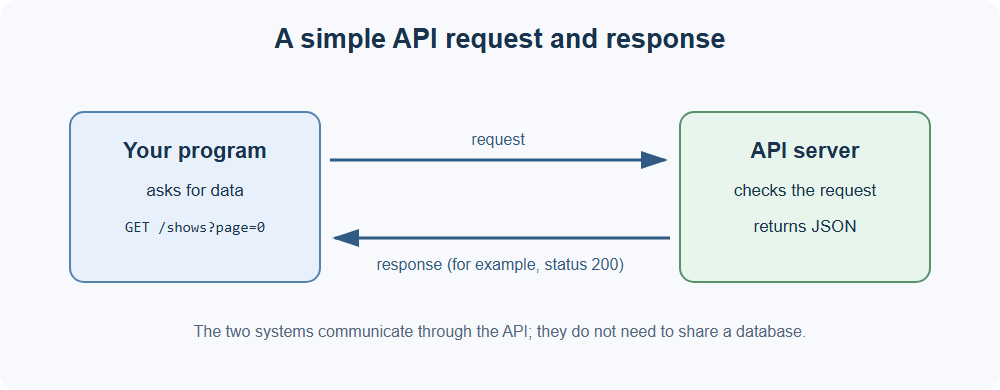

### **Request pages and build a DataFrame**

Normally we follow the pattern `request → JSON → selected columns → DataFrame`. It uses `requests.get()`; this version uses Python’s built-in `urllib` so it needs no API-client package. The example uses a public TV data API and falls back to small sample records if the network is unavailable.

In [3]:
import json
from urllib.request import Request, urlopen

# The API numbers its pages from 0. Try two pages to show pagination.
shows = []
try:
    for page in range(2):
        url = f"https://api.tvmaze.com/shows?page={page}"
        request = Request(url, headers={"User-Agent": "ML-notebook-learning-example"})
        with urlopen(request, timeout=5) as response:
            print(f"Page {page}: HTTP {response.status}")
            shows.extend(json.loads(response.read().decode("utf-8"))[:3])
except Exception as error:
    print(f"Could not reach the API ({type(error).__name__}); using sample JSON instead.")
    shows = [
        {"id": 1, "name": "Example Show A", "language": "English", "premiered": "2020-01-01"},
        {"id": 2, "name": "Example Show B", "language": "Urdu", "premiered": "2021-01-01"},
        {"id": 3, "name": "Example Show C", "language": "English", "premiered": "2022-01-01"},
    ]

shows_data = pd.DataFrame(shows)
columns = [column for column in ["id", "name", "language", "premiered"] if column in shows_data.columns]
shows_data = shows_data[columns]
print(shows_data.head().to_string(index=False))

Page 0: HTTP 200
Page 1: HTTP 200
 id               name language  premiered
  1     Under the Dome  English 2013-06-24
  2 Person of Interest  English 2011-09-22
  3             Bitten  English 2014-01-11
250      Kirby Buckets  English 2014-10-20
251      Downton Abbey  English 2010-09-26


With one-based page numbers, `range(1, pages + 1)` visits every page because Python excludes the stop value. This API starts at page 0, so its documentation determines the loop above.

In older code we were using `DataFrame.append()`, which newer pandas versions removed; `pd.concat()` is the current way to combine collected page tables. Save a finished table with `to_csv()` when you need a reusable file.

**You can use collected data to build a Kaggle dataset, publish notebooks, enter competitions, or join discussions. RapidAPI is one directory for finding APIs; check each API’s access terms and limits.**

<!-- Source transcription: transcription/8.3.md -->
## **Web scraping**

Some websites do not offer an API, so we can read the HTML they return and extract the fields we need. First inspect the page and find a repeated container, then select the tags and classes inside each one. Scrape only pages you are allowed to access; a browser header does not override site rules.

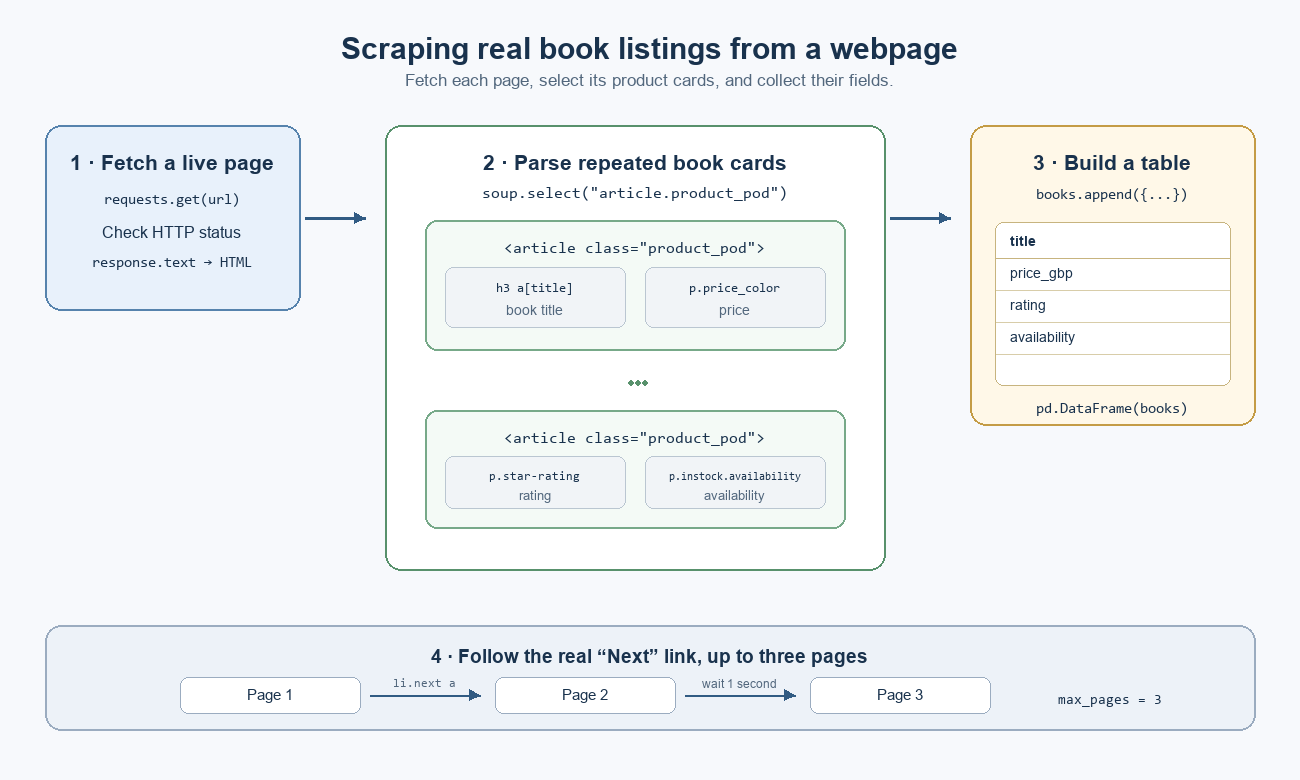

This code sends a request to the live book catalog, parses each page’s HTML with BeautifulSoup, and extracts each book’s title, price, rating, and availability. It follows the “Next” link for up to three pages, then stores the results in a pandas DataFrame.

In [4]:
import time
from urllib.parse import urljoin

import pandas as pd
import requests
from bs4 import BeautifulSoup

url = "https://books.toscrape.com/"
max_pages = 3
books = []

for page_number in range(1, max_pages + 1):
    response = requests.get(url, timeout=20)
    response.raise_for_status()  # Stop if the site refuses or fails the request.

    soup = BeautifulSoup(response.text, "html.parser")
    cards = soup.select("article.product_pod")

    for card in cards:
        title = card.select_one("h3 a")["title"]
        price_text = card.select_one("p.price_color").get_text(strip=True)
        price = float("".join(ch for ch in price_text if ch.isdigit() or ch == "."))

        rating_classes = card.select_one("p.star-rating").get("class", [])
        rating = next((name for name in rating_classes if name != "star-rating"), None)

        availability = card.select_one("p.instock.availability").get_text(" ", strip=True)

        books.append({
            "title": title,
            "price_gbp": price,
            "rating": rating,
            "availability": availability,
        })

    print(f"Page {page_number}: HTTP {response.status_code}; {len(cards)} books")

    next_link = soup.select_one("li.next a")
    if next_link is None:
        break

    url = urljoin(response.url, next_link["href"])
    time.sleep(1)  # Pause briefly between page requests.

books_df = pd.DataFrame(books)
books_df.head()

Page 1: HTTP 200; 20 books
Page 2: HTTP 200; 20 books
Page 3: HTTP 200; 20 books


,title,price_gbp,rating,availability
0,A Light in the Attic,51.77,Three,In stock
1,Tipping the Velvet,53.74,One,In stock
2,Soumission,50.10,One,In stock
3,Sharp Objects,47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock
